In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [9]:
df = pd.read_csv("healthcare-dataset-stroke-data.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [10]:
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [11]:
df.tail()


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
5105,18234,Female,80.0,1,0,Yes,Private,Urban,83.75,NaN,never smoked,0
5106,44873,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.0,never smoked,0
5107,19723,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.6,never smoked,0
5108,37544,Male,51.0,0,0,Yes,Private,Rural,166.29,25.6,formerly smoked,0
5109,44679,Female,44.0,0,0,Yes,Govt_job,Urban,85.28,26.2,Unknown,0


In [12]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Dataset shape:", df.shape)

Number of rows: 5110
Number of columns: 12
Dataset shape: (5110, 12)


In [13]:
print("Column names:")
print(df.columns.tolist())

Column names:
['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']


In [14]:
df.dtypes

,0
id,int64
gender,object
age,float64
hypertension,int64
heart_disease,int64
ever_married,object
work_type,object
Residence_type,object
avg_glucose_level,float64
bmi,float64


In [15]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [16]:
# Identify numerical and categorical columns

numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_columns = df.select_dtypes(include=['object']).columns.tolist()

print("Numerical columns:")
print(numerical_columns)

print("\nCategorical columns:")
print(categorical_columns)

Numerical columns:
['id', 'age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'stroke']

Categorical columns:
['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']


In [17]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [18]:
df[['age', 'avg_glucose_level', 'bmi']].describe()

,age,avg_glucose_level,bmi
count,5110.000000,5110.000000,4909.000000
mean,43.226614,106.147677,28.893237
std,22.612647,45.283560,7.854067
min,0.080000,55.120000,10.300000
25%,25.000000,77.245000,23.500000
50%,45.000000,91.885000,28.100000
75%,61.000000,114.090000,33.100000
max,82.000000,271.740000,97.600000


In [19]:
for column in categorical_columns:
    print(f"\nFrequency counts for {column}:")
    print(df[column].value_counts())


Frequency counts for gender:
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

Frequency counts for ever_married:
ever_married
Yes    3353
No     1757
Name: count, dtype: int64

Frequency counts for work_type:
work_type
Private          2925
Self-employed     819
children          687
Govt_job          657
Never_worked       22
Name: count, dtype: int64

Frequency counts for Residence_type:
Residence_type
Urban    2596
Rural    2514
Name: count, dtype: int64

Frequency counts for smoking_status:
smoking_status
never smoked       1892
Unknown            1544
formerly smoked     885
smokes              789
Name: count, dtype: int64


In [20]:
print("Target variable: stroke")
print("\nTarget distribution:")
print(df['stroke'].value_counts())

Target variable: stroke

Target distribution:
stroke
0    4861
1     249
Name: count, dtype: int64


### Step 3: Identification of Data Types and Basic Statistical Analysis

The dataset contains numerical and categorical features. The numerical features include age, average glucose level, BMI, hypertension, heart disease, and stroke. The categorical features include gender, ever married, work type, residence type, and smoking status.

The columns hypertension, heart disease, and stroke contain binary values (0 and 1). The ID column is an identifier and is not considered a meaningful analytical feature.

The `describe()` function was used to calculate summary statistics such as mean, standard deviation, minimum, maximum, and quartiles for numerical data. Frequency counts were used to examine the distribution of categorical variables.

The `stroke` column was identified as the target variable for a possible future prediction task. Model training was not performed because it is not required for this activity.

In [21]:
# Count missing values in each column

missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64


In [22]:
# Calculate missing-value percentage

missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_table = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': missing_percentage
})

missing_table

,Missing Values,Missing Percentage
id,0,0.000000
gender,0,0.000000
age,0,0.000000
hypertension,0,0.000000
heart_disease,0,0.000000
ever_married,0,0.000000
work_type,0,0.000000
Residence_type,0,0.000000
avg_glucose_level,0,0.000000
bmi,201,3.933464


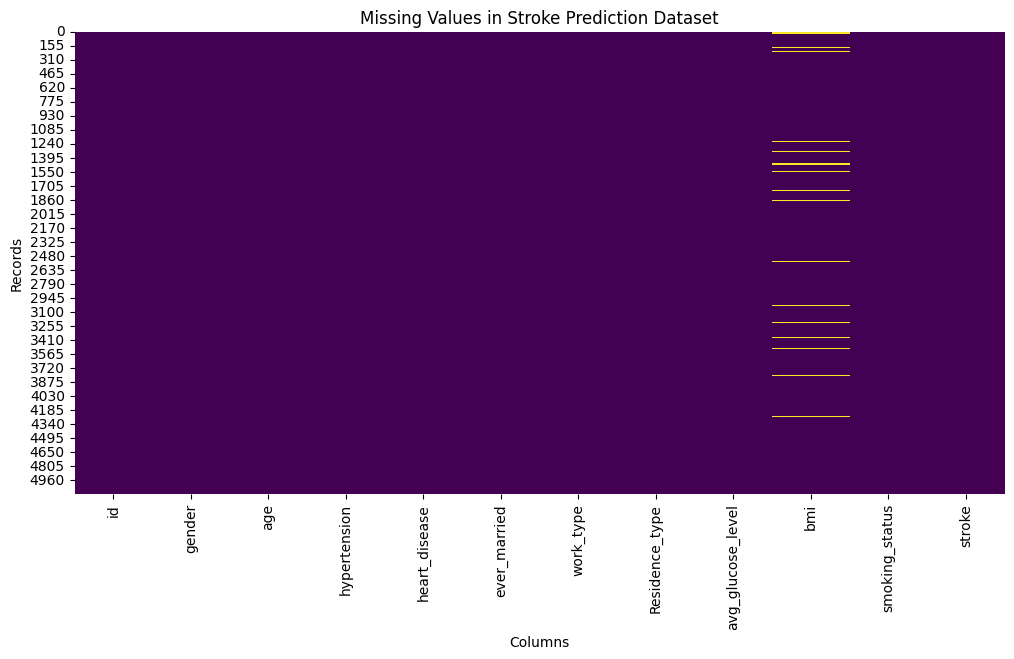

In [23]:
plt.figure(figsize=(12, 6))

sns.heatmap(df.isnull(), cbar=False, cmap='viridis')

plt.title("Missing Values in Stroke Prediction Dataset")
plt.xlabel("Columns")
plt.ylabel("Records")

plt.show()

### Step 4: Missing-Value Analysis

Missing values were checked in all columns using the `isnull().sum()` function. The missing-value percentage was calculated for each column.

The analysis identified 201 missing values in the BMI column, representing approximately 3.93% of the total records. All other columns had zero missing values.

The missing values were visualized using a heatmap. Since BMI is a numerical feature and only a small percentage of its values are missing, median imputation was selected as an appropriate method to handle the missing data. The original dataset will be preserved before performing the cleaning operation.

In [24]:
# Create a backup of the original dataset
df_original = df.copy()

# Create a separate dataset for cleaning
cleaned_df = df.copy()

print("Original dataset preserved.")
print("Working copy created.")

Original dataset preserved.
Working copy created.


In [25]:
bmi_median = cleaned_df['bmi'].median()

print("Median BMI:", bmi_median)

Median BMI: 28.1


In [26]:
# Fill missing BMI values using median imputation

cleaned_df['bmi'] = cleaned_df['bmi'].fillna(bmi_median)

print("Missing BMI values handled successfully!")

Missing BMI values handled successfully!


In [27]:
# Check missing values after imputation

print("Missing values after cleaning:")
print(cleaned_df.isnull().sum())

Missing values after cleaning:
id                   0
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64


In [28]:
print("Missing BMI before cleaning:", df_original['bmi'].isnull().sum())
print("Missing BMI after cleaning:", cleaned_df['bmi'].isnull().sum())

print("\nOriginal dataset shape:", df_original.shape)
print("Cleaned dataset shape:", cleaned_df.shape)

Missing BMI before cleaning: 201
Missing BMI after cleaning: 0

Original dataset shape: (5110, 12)
Cleaned dataset shape: (5110, 12)


### Step 5: Handling Missing Values

A copy of the original dataset was created to preserve the raw data. A separate working copy was used for preprocessing.

The BMI column contained 201 missing values. Since BMI is a numerical feature and its distribution may be affected by outliers, median imputation was selected instead of mean imputation.

The median BMI was calculated using the available values and used to replace the missing entries in the BMI column. No rows or columns were deleted. After imputation, the dataset was checked again, and the missing BMI values were successfully handled while retaining all 5,110 records and 12 columns.

In [29]:
# Check duplicate rows

duplicate_count = cleaned_df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [30]:
print("Duplicate IDs:", cleaned_df['id'].duplicated().sum())
print("Unique IDs:", cleaned_df['id'].nunique())

Duplicate IDs: 0
Unique IDs: 5110


In [31]:
categorical_columns = [
    'gender',
    'ever_married',
    'work_type',
    'Residence_type',
    'smoking_status'
]

for column in categorical_columns:
    print(f"\nUnique values in {column}:")
    print(cleaned_df[column].unique())


Unique values in gender:
['Male' 'Female' 'Other']

Unique values in ever_married:
['Yes' 'No']

Unique values in work_type:
['Private' 'Self-employed' 'Govt_job' 'children' 'Never_worked']

Unique values in Residence_type:
['Urban' 'Rural']

Unique values in smoking_status:
['formerly smoked' 'never smoked' 'smokes' 'Unknown']


In [32]:
binary_columns = ['hypertension', 'heart_disease', 'stroke']

for column in binary_columns:
    print(f"\nValues in {column}:")
    print(cleaned_df[column].value_counts())


Values in hypertension:
hypertension
0    4612
1     498
Name: count, dtype: int64

Values in heart_disease:
heart_disease
0    4834
1     276
Name: count, dtype: int64

Values in stroke:
stroke
0    4861
1     249
Name: count, dtype: int64


In [33]:
cleaned_df[['age', 'avg_glucose_level', 'bmi']].describe()

,age,avg_glucose_level,bmi
count,5110.000000,5110.000000,5110.000000
mean,43.226614,106.147677,28.862035
std,22.612647,45.283560,7.699562
min,0.080000,55.120000,10.300000
25%,25.000000,77.245000,23.800000
50%,45.000000,91.885000,28.100000
75%,61.000000,114.090000,32.800000
max,82.000000,271.740000,97.600000


### Step 6: Duplicate Records and Data Consistency

Duplicate records were checked using the `duplicated()` function, and no duplicate rows were found. A duplicate ID check was also performed. All 5,110 records had unique IDs, indicating that there were no repeated identifiers.

The binary columns `hypertension`, `heart_disease`, and `stroke` were examined. All three columns contained only valid binary values (0 and 1).

The hypertension column contained 4,612 records with value 0 and 498 with value 1. The heart disease column contained 4,834 records with value 0 and 276 with value 1. The stroke column contained 4,861 records with value 0 and 249 with value 1.

The stroke target variable showed class imbalance, as the number of records without stroke was significantly higher than the number of records with stroke. These observations were recorded for further analysis.


In [34]:
cleaned_df[['age', 'avg_glucose_level', 'bmi']].describe()

,age,avg_glucose_level,bmi
count,5110.000000,5110.000000,5110.000000
mean,43.226614,106.147677,28.862035
std,22.612647,45.283560,7.699562
min,0.080000,55.120000,10.300000
25%,25.000000,77.245000,23.800000
50%,45.000000,91.885000,28.100000
75%,61.000000,114.090000,32.800000
max,82.000000,271.740000,97.600000


### Step 7: Numerical Summary and Range Analysis

The numerical columns age, avg_glucose_level, and bmi were analyzed using the describe() function. This provided the count, mean, standard deviation, minimum, quartiles, median, and maximum values.

The dataset contains 5,110 observations in each of the three numerical columns. The average age is 43.23 years, the average glucose level is 106.15, and the average BMI is 28.86.

The age values range from 0.08 to 82 years. The glucose level ranges from 55.12 to 271.74, while BMI ranges from 10.30 to 97.60. The maximum BMI value appears unusually high and may represent a potential outlier. Such values were observed but not automatically removed because their validity could not be confirmed from the dataset alone.


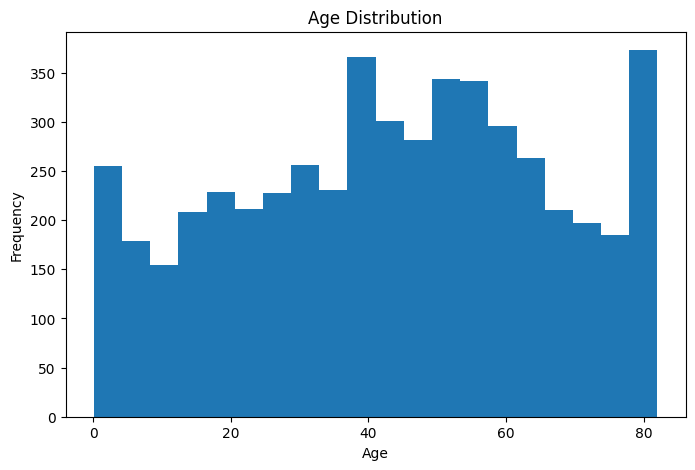

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(cleaned_df['age'], bins=20)
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

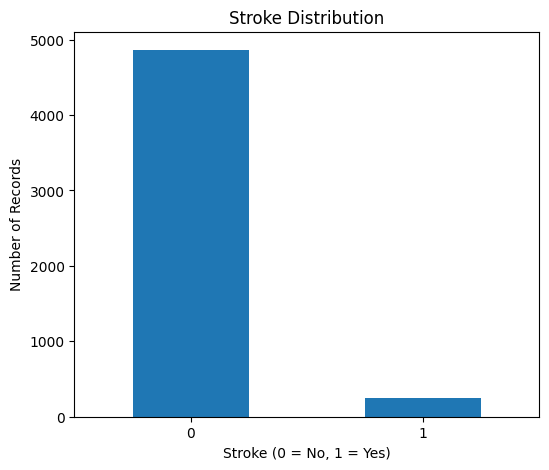

In [36]:
plt.figure(figsize=(6, 5))
cleaned_df['stroke'].value_counts().plot(kind='bar')
plt.title('Stroke Distribution')
plt.xlabel('Stroke (0 = No, 1 = Yes)')
plt.ylabel('Number of Records')
plt.xticks(rotation=0)
plt.show()

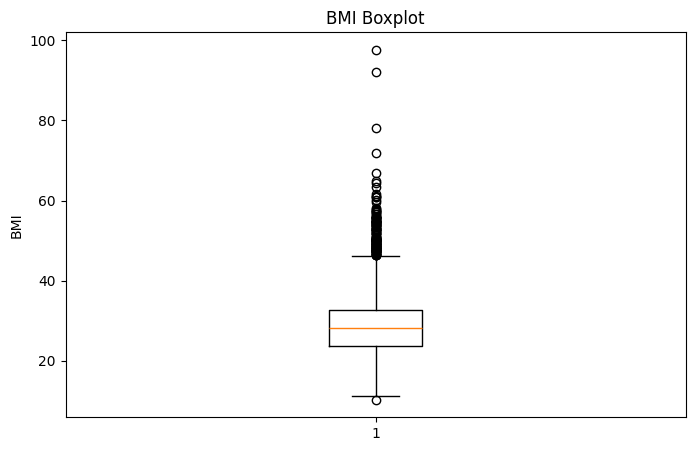

In [37]:
plt.figure(figsize=(8, 5))
plt.boxplot(cleaned_df['bmi'])
plt.title('BMI Boxplot')
plt.ylabel('BMI')
plt.show()

### Step 8: Exploratory Data Analysis (EDA)

Exploratory Data Analysis was performed using histograms, bar charts, and boxplots to understand the distribution of data.

**Age Distribution:** The histogram shows that the dataset contains records from very young individuals to older adults, with observations distributed across a wide age range. The age distribution is not uniform.

**Stroke Distribution:** The bar chart shows that 4,861 records belong to the no-stroke class, while 249 records belong to the stroke class. This indicates significant class imbalance in the target variable.

**BMI Boxplot:** The boxplot shows the median BMI of approximately 28.1 and several potential outliers above the upper whisker. Some BMI values are unusually high. These observations were identified but not removed during this activity.

The visualizations helped understand the dataset's numerical distributions, target-class imbalance, and potential outliers.


In [38]:
# Create a copy for final preprocessing
prepared_df = cleaned_df.copy()

# Remove ID because it is only an identifier, not a useful predictive feature
prepared_df = prepared_df.drop(columns=['id'])

# Identify categorical columns
categorical_columns = [
    'gender',
    'ever_married',
    'work_type',
    'Residence_type',
    'smoking_status'
]

# Apply One-Hot Encoding
prepared_df = pd.get_dummies(
    prepared_df,
    columns=categorical_columns,
    dtype=int
)

# Display the new dataset
prepared_df.head()

,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,gender_Female,gender_Male,gender_Other,ever_married_No,...,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,67.0,0,1,228.69,36.6,1,0,1,0,0,...,0,1,0,0,0,1,0,1,0,0
1,61.0,0,0,202.21,28.1,1,1,0,0,0,...,0,0,1,0,1,0,0,0,1,0
2,80.0,0,1,105.92,32.5,1,0,1,0,0,...,0,1,0,0,1,0,0,0,1,0
3,49.0,0,0,171.23,34.4,1,1,0,0,0,...,0,1,0,0,0,1,0,0,0,1
4,79.0,1,0,174.12,24.0,1,1,0,0,0,...,0,0,1,0,1,0,0,0,1,0


In [39]:
prepared_df.shape

(5110, 22)

In [40]:
prepared_df.dtypes

,0
age,float64
hypertension,int64
heart_disease,int64
avg_glucose_level,float64
bmi,float64
stroke,int64
gender_Female,int64
gender_Male,int64
gender_Other,int64
ever_married_No,int64


In [41]:
from sklearn.preprocessing import StandardScaler

# Select continuous numerical columns
numerical_columns = ['age', 'avg_glucose_level', 'bmi']

# Create the scaler
scaler = StandardScaler()

# Apply standardization
prepared_df[numerical_columns] = scaler.fit_transform(
    prepared_df[numerical_columns]
)

# Display the scaled data
prepared_df[numerical_columns].head()

,age,avg_glucose_level,bmi
0,1.051434,2.706375,1.005086
1,0.786070,2.121559,-0.098981
2,1.626390,-0.005028,0.472536
3,0.255342,1.437358,0.719327
4,1.582163,1.501184,-0.631531


In [42]:
prepared_df[numerical_columns].describe()

,age,avg_glucose_level,bmi
count,5.110000e+03,5.110000e+03,5.110000e+03
mean,5.005781e-17,1.001156e-16,-4.449583e-17
std,1.000098e+00,1.000098e+00,1.000098e+00
min,-1.908261e+00,-1.126958e+00,-2.411027e+00
25%,-8.061152e-01,-6.383223e-01,-6.575089e-01
50%,7.843218e-02,-3.149945e-01,-9.898092e-02
75%,7.860701e-01,1.754080e-01,5.115031e-01
max,1.714845e+00,3.657145e+00,8.928390e+00


### Step 9: Feature Scaling

Feature scaling was performed on the continuous numerical columns age, avg_glucose_level, and bmi using StandardScaler from the Scikit-learn library.

StandardScaler transforms the numerical features so that their mean is approximately zero and their standard deviation is approximately one. After scaling, the mean values of all three columns were very close to 0, and their standard deviation values were approximately 1.

The binary columns hypertension, heart_disease, and stroke were not scaled. The target column stroke was retained in its original binary format. Feature scaling helped bring the continuous numerical features onto a comparable scale. Scaling was demonstrated on the dataset for this preparation activity; in an actual model-training workflow, the scaler should be fitted only on the training data to prevent data leakage.


In [43]:
# Save the prepared dataset
prepared_df.to_csv('stroke_dataset_prepared.csv', index=False)

print("Prepared dataset saved successfully!")

Prepared dataset saved successfully!


In [44]:
# Final verification
print("Final Shape:", prepared_df.shape)

print("\nMissing Values:")
print(prepared_df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(prepared_df.duplicated().sum())

print("\nFirst 5 Rows:")
display(prepared_df.head())

Final Shape: (5110, 22)

Missing Values:
0

Duplicate Rows:
0

First 5 Rows:


,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,gender_Female,gender_Male,gender_Other,ever_married_No,...,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,1.051434,0,1,2.706375,1.005086,1,0,1,0,0,...,0,1,0,0,0,1,0,1,0,0
1,0.786070,0,0,2.121559,-0.098981,1,1,0,0,0,...,0,0,1,0,1,0,0,0,1,0
2,1.626390,0,1,-0.005028,0.472536,1,0,1,0,0,...,0,1,0,0,1,0,0,0,1,0
3,0.255342,0,0,1.437358,0.719327,1,1,0,0,0,...,0,1,0,0,0,1,0,0,0,1
4,1.582163,1,0,1.501184,-0.631531,1,1,0,0,0,...,0,0,1,0,1,0,0,0,1,0


In [ ]:
## Conclusion

In this activity, the Stroke Prediction Dataset was selected and prepared for future machine learning work. The dataset was inspected to understand its structure, data types, and quality. Missing values in the BMI column were handled using median imputation, duplicate records were checked, and categorical values were examined for consistency.

Exploratory Data Analysis was performed using histograms, bar charts, and boxplots to understand the distributions of age, stroke cases, and BMI. Categorical variables were converted into numerical format using One-Hot Encoding, and continuous numerical features were standardized using StandardScaler.

The final prepared dataset contains 5,110 rows and 22 columns, with zero missing values and zero duplicate rows. The cleaned dataset was saved as a CSV file and is ready for further machine learning analysis. No prediction model was developed, as the activity focused only on dataset preparation.


In [45]:
from google.colab import files

files.download('stroke_dataset_prepared.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>